# Installing YOLOv10 and Disabling W&B Logging

In [1]:
!pip install ultralytics
!wandb disabled

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.6/914.6 kB 21.1 MB/s eta 0:00:0000:01
W&B disabled.


# Training YOLOv10 Model for Fire Detection

In [2]:
!yolo train model=yolov10n.pt data=/kaggle/input/fire-detection2/data.yaml epochs=50 imgsz=640 batch=64

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
100%|███████████████████████████████████████| 5.59M/5.59M [00:00<00:00, 107MB/s]
Ultralytics 8.3.69 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov10n.pt, data=/kaggle/input/fire-detection2/data.yaml, epochs=50, time=None, patience=100, batch=64, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0

# Displaying Training Results Image

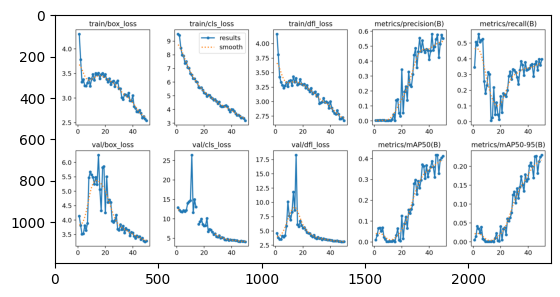

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/kaggle/working/runs/detect/train/results.png')
imgplot = plt.imshow(img)
plt.show()

# Displaying Confusion Matrix (Normalized)

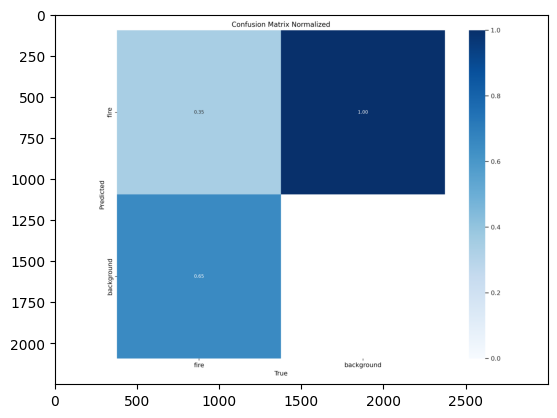

In [4]:
img = mpimg.imread('/kaggle/working/runs/detect/train/confusion_matrix_normalized.png')
imgplot = plt.imshow(img)
plt.show()

# Displaying Precision Curve

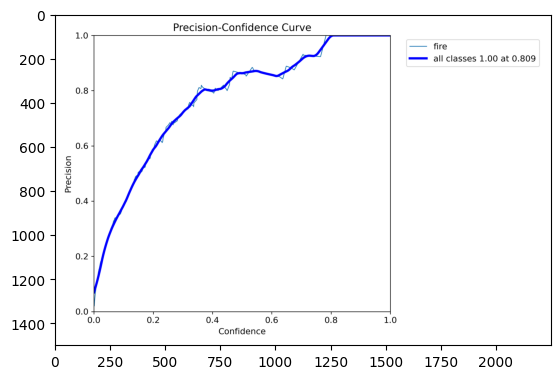

In [5]:
img = mpimg.imread('/kaggle/working/runs/detect/train/P_curve.png')
imgplot = plt.imshow(img)
plt.show()

# Displaying Predicted Validation Batch Image

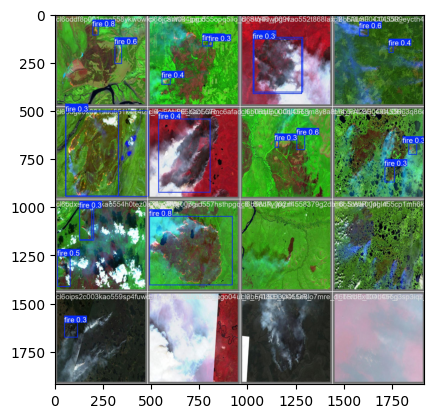

In [6]:
img = mpimg.imread('/kaggle/working/runs/detect/train/val_batch0_pred.jpg')
imgplot = plt.imshow(img)
plt.show()

# Making Predictions on Test Images

In [7]:
!yolo task=detect mode=predict model="/kaggle/working/runs/detect/train/weights/best.pt" device=0 source="/kaggle/input/fire-detection/Fire-Detection/test/images" save=True

Ultralytics 8.3.69 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,694,806 parameters, 0 gradients, 8.2 GFLOPs

Traceback (most recent call last):
  File "/opt/conda/bin/yolo", line 8, in <module>
    sys.exit(entrypoint())
  File "/opt/conda/lib/python3.10/site-packages/ultralytics/cfg/__init__.py", line 986, in entrypoint
    getattr(model, mode)(**overrides)  # default args from model
  File "/opt/conda/lib/python3.10/site-packages/ultralytics/engine/model.py", line 558, in predict
    return self.predictor.predict_cli(source=source) if is_cli else self.predictor(source=source, stream=stream)
  File "/opt/conda/lib/python3.10/site-packages/ultralytics/engine/predictor.py", line 190, in predict_cli
    for _ in gen:  # sourcery skip: remove-empty-nested-block, noqa
  File "/opt/conda/lib/python3.10/site-packages/torch/utils/_contextlib.py", line 35, in generator_context
    response = gen.send(None)
  File "/opt/conda/lib/python3.10/si

# Evaluate the Model on the Test Set

In [8]:
!yolo val model="/kaggle/working/runs/detect/train/weights/best.pt" data=/kaggle/input/fire-detection2/data.yaml


Ultralytics 8.3.69 🚀 Python-3.10.13 torch-2.1.2 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,694,806 parameters, 0 gradients, 8.2 GFLOPs
val: Scanning /kaggle/input/fire-detection2/valid/labels... 75 images, 1 backgro
val: WARNING ⚠️ Cache directory /kaggle/input/fire-detection2/valid is not writeable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  m
                   all         75        156       0.55      0.391      0.412      0.229
Speed: 4.5ms preprocess, 24.4ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val
